In [9]:
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

archive = root / "data" / "raw" / "OC-20250526T142605Z-1-001.zip"

with ZipFile(archive) as outer:
    with ZipFile(BytesIO(outer.read("OC/Agriculture Crop Yield.zip"))) as inner:
        agriculture_raw = pd.read_csv(inner.open("crop_yield.csv"))
    with ZipFile(BytesIO(outer.read("OC/Crop Yield Prediction Dataset.zip"))) as inner:
        history_raw = pd.read_csv(inner.open("yield_df.csv"))

target = "Yield_tons_per_hectare"
history_key = ["Area", "Item", "Year"]

for name, frame in {
    "Agriculture Crop Yield": agriculture_raw,
    "Crop Yield Prediction": history_raw,
}.items():
    print(name, frame.shape)
    display(pd.DataFrame({
        "type": frame.dtypes,
        "valeurs_manquantes": frame.isna().sum(),
    }))

print("Rendements négatifs :", agriculture_raw[target].lt(0).sum())
agriculture = (
    agriculture_raw.drop_duplicates()
    .dropna()
    .loc[lambda frame: frame[target].ge(0)]
    .reset_index(drop=True)
)

print("Observations agricoles conservées :", len(agriculture))
print("Clés historiques pays × culture × année :", 
      len(history_raw[history_key].drop_duplicates()))

Agriculture Crop Yield (1000000, 10)


,type,valeurs_manquantes
Region,str,0
Soil_Type,str,0
Crop,str,0
Rainfall_mm,float64,0
Temperature_Celsius,float64,0
Fertilizer_Used,bool,0
Irrigation_Used,bool,0
Weather_Condition,str,0
Days_to_Harvest,int64,0
Yield_tons_per_hectare,float64,0


Crop Yield Prediction (28242, 8)


,type,valeurs_manquantes
Unnamed: 0,int64,0
Area,str,0
Item,str,0
Year,int64,0
hg/ha_yield,int64,0
average_rain_fall_mm_per_year,float64,0
pesticides_tonnes,float64,0
avg_temp,float64,0


Rendements négatifs : 231
Observations agricoles conservées : 999769
Clés historiques pays × culture × année : 13130


,Variance expliquée (%)
CP1,25.08
CP2,25.02
CP3,24.97
CP4,24.93


,CP1,CP2,CP3,CP4
Rainfall_mm,-0.468,-0.312,0.814,0.144
Temperature_Celsius,0.466,-0.647,0.124,-0.591
Irrigation_Used,0.324,0.689,0.518,-0.390
Fertilizer_Used,0.678,-0.100,0.229,0.691


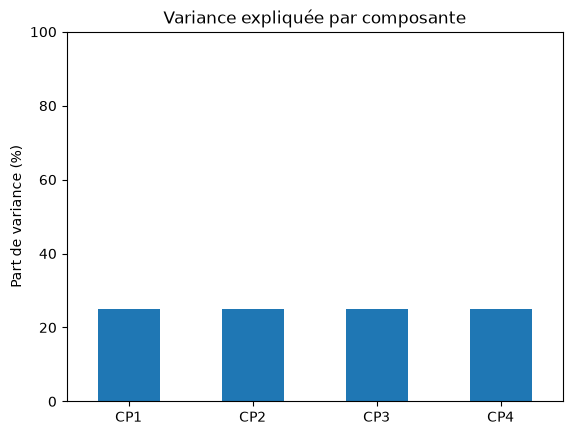

,Corrélation
Rainfall_mm,0.765
Fertilizer_Used,0.442
Irrigation_Used,0.353
Temperature_Celsius,0.085


In [10]:
features = [
    "Rainfall_mm", "Temperature_Celsius",
    "Irrigation_Used", "Fertilizer_Used",
]

X = agriculture[features].astype(float)
pca = PCA().fit(StandardScaler().fit_transform(X))
components = [f"CP{i}" for i in range(1, pca.n_components_ + 1)]

variance = pd.Series(
    pca.explained_variance_ratio_ * 100,
    index=components,
    name="Variance expliquée (%)",
)
display(variance.round(2).to_frame())
display(pd.DataFrame(
    pca.components_.T, index=features, columns=components
).round(3))

ax = variance.plot.bar(rot=0, ylim=(0, 100), title="Variance expliquée par composante")
ax.set_ylabel("Part de variance (%)")
plt.show()

correlations = (
    agriculture[features + [target]]
    .astype(float)
    .corr()[target]
    .drop(target)
)
display(correlations.sort_values(ascending=False).round(3).to_frame("Corrélation"))

In [11]:
crop_names = {
    "Maize": "Maize",
    "Rice, paddy": "Rice",
    "Soybeans": "Soybean",
    "Wheat": "Wheat",
}

annual = (
    history_raw.groupby(history_key, as_index=False)
    .agg(
        rainfall_mm=("average_rain_fall_mm_per_year", "median"),
        temperature_c=("avg_temp", "median"),
        pesticides_tonnes=("pesticides_tonnes", "median"),
    )
)

annual["Crop"] = annual["Item"].map(crop_names)

profiles = (
    annual.dropna(subset=["Crop"])
    .groupby("Crop", as_index=False)
    .agg(
        hist_country_year_count=("Year", "size"),
        hist_rainfall_mm_median=("rainfall_mm", "median"),
        hist_temperature_c_median=("temperature_c", "median"),
        hist_pesticides_tonnes_median=("pesticides_tonnes", "median"),
    )
)

consolidated = agriculture.merge(
    profiles, on="Crop", how="left", validate="many_to_one"
)
consolidated["has_historical_profile"] = (
    consolidated["hist_country_year_count"].notna()
)

assert len(consolidated) == len(agriculture)
display(profiles)
display(consolidated.groupby(
    ["Crop", "has_historical_profile"]
).size().rename("observations").to_frame())

output = root / "data" / "processed" / "crop_yield_consolidated.csv"
output.parent.mkdir(parents=True, exist_ok=True)
consolidated.to_csv(output, index=False)
print(f"CSV consolidé : {output}")

,Crop,hist_country_year_count,hist_rainfall_mm_median,hist_temperature_c_median,hist_pesticides_tonnes_median
0,Maize,2028,867.0,20.240,2166.500
1,Rice,1502,1131.5,21.570,2961.365
2,Soybean,1242,1020.0,18.475,4358.730
3,Wheat,1810,700.0,17.130,3101.340


,,observations
Crop,has_historical_profile,
Barley,False,166727
Cotton,False,166548
Maize,True,166785
Rice,True,166754
Soybean,True,166315
Wheat,True,166640


CSV consolidé : c:\Users\mouto\Documents\Jedha\OCR_Projects\OCR_Projet_12_analyse\data\processed\crop_yield_consolidated.csv


In [12]:
pip install mlflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import sys

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

sys.path.insert(0, str(root))
from src.models.train_regression import build_preprocessor

base_cols = [
    "Region", "Soil_Type", "Crop", "Rainfall_mm",
    "Temperature_Celsius", "Fertilizer_Used",
    "Irrigation_Used", "Weather_Condition",
]
hist_cols = [col for col in profiles.columns if col != "Crop"]
hist_cols += ["has_historical_profile"]

train_idx, _ = train_test_split(
    consolidated.index, test_size=0.20, random_state=42
)
train = consolidated.loc[train_idx].sample(n=100_000, random_state=42)
y_train = train[target]
crops = sorted(train["Crop"].unique())

def add_interactions(frame):
    interactions = {
        f"{crop}__{variable}": (
            frame["Crop"].eq(crop) * frame[variable].astype(float)
        )
        for crop in crops[1:]
        for variable in ["Rainfall_mm", "Irrigation_Used"]
    }
    return frame.assign(**interactions)

configs = {
    "Référence": (base_cols, None),
    "Avec historique": (base_cols + hist_cols, None),
    "Avec interactions": (base_cols, add_interactions),
}

cv = list(KFold(n_splits=5, shuffle=True, random_state=42).split(train))
models = {}
fold_scores = {}

for name, (columns, transform) in configs.items():
    X_train = train[columns]
    steps = []
    schema = X_train

    if transform is not None:
        steps.append(("interactions", FunctionTransformer(transform)))
        schema = transform(X_train.head(1))

    steps.extend([
        ("preprocess", build_preprocessor(schema)),
        ("model", LinearRegression()),
    ])
    model = Pipeline(steps)
    fold_scores[name] = -cross_val_score(
        model, X_train, y_train, cv=cv,
        scoring="neg_mean_absolute_error", error_score="raise",
    )
    models[name] = model.fit(X_train, y_train)

scores = pd.DataFrame(fold_scores)
display(pd.DataFrame({
    "MAE moyenne (t/ha)": scores.mean(),
    "Écart-type (t/ha)": scores.std(ddof=0),
    "Δ MAE vs référence (t/ha)": scores.sub(scores["Référence"], axis=0).mean(),
}).round(6))

,MAE moyenne (t/ha),Écart-type (t/ha),Δ MAE vs référence (t/ha)
Référence,0.398626,0.001483,0.000000
Avec historique,0.398626,0.001483,-0.000000
Avec interactions,0.398651,0.001460,0.000025


In [14]:
contexts = (
    train[base_cols].drop(columns="Crop")
    .sample(n=2_000, random_state=42)
    .reset_index(drop=True)
)

scenarios = (
    contexts.rename_axis("scenario").reset_index()
    .merge(pd.DataFrame({"Crop": crops}), how="cross")
    .merge(profiles, on="Crop", how="left", validate="many_to_one")
)
scenarios["has_historical_profile"] = scenarios["hist_country_year_count"].notna()

ranking_summary = []

for name, model in models.items():
    columns = configs[name][0]
    simulations = scenarios.assign(
        prediction=model.predict(scenarios[columns])
    )
    ranking = simulations.sort_values(
        ["scenario", "prediction", "Crop"],
        ascending=[True, False, True],
    )

    winners = ranking.groupby("scenario").head(1)["Crop"].value_counts()
    top_two = ranking.groupby("scenario").head(2)
    gaps_kg_ha = -1_000 * top_two.groupby("scenario")["prediction"].diff().dropna()

    ranking_summary.append({
        "Configuration": name,
        "Cultures arrivées premières": winners.to_dict(),
        "Écart médian (kg/ha)": gaps_kg_ha.median(),
        "95e percentile de l’écart (kg/ha)": gaps_kg_ha.quantile(0.95),
    })

display(pd.DataFrame(ranking_summary).round(2))

,Configuration,Cultures arrivées premières,Écart médian (kg/ha),95e percentile de l’écart (kg/ha)
0,Référence,{'Soybean': 2000},0.70,0.70
1,Avec historique,{'Soybean': 2000},0.70,0.70
2,Avec interactions,"{'Soybean': 992, 'Rice': 983, 'Cotton': 25}",2.34,6.63


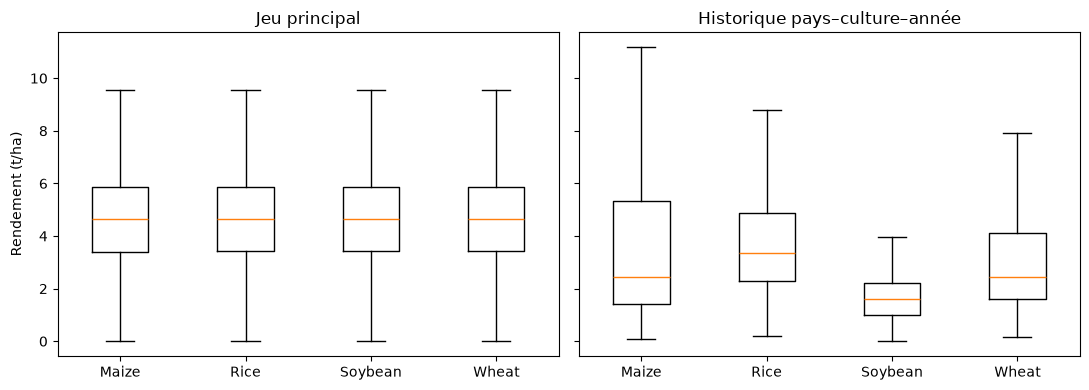

,Source,Culture,Observations,Rendement médian (t/ha),Corrélation pluie–rendement,Corrélation température–rendement
0,Jeu principal,Maize,166785,4.643,0.765,0.085
1,Jeu principal,Rice,166754,4.653,0.765,0.082
2,Jeu principal,Soybean,166315,4.658,0.763,0.087
3,Jeu principal,Wheat,166640,4.656,0.764,0.082
4,Historique pays–culture–année,Maize,2028,2.449,-0.131,-0.477
5,Historique pays–culture–année,Rice,1502,3.355,-0.121,-0.295
6,Historique pays–culture–année,Soybean,1242,1.620,-0.011,-0.261
7,Historique pays–culture–année,Wheat,1810,2.432,-0.049,-0.428


Pays avec une pluviométrie constante dans l’historique : 100 / 100


In [15]:
historique = history_raw.groupby(history_key, as_index=False).agg(
    rendement_hg_ha=("hg/ha_yield", "median"),
    pluie_mm=("average_rain_fall_mm_per_year", "median"),
    temperature_c=("avg_temp", "median"),
)
historique["Crop"] = historique["Item"].map(crop_names)
historique = historique.loc[
    historique["Crop"].notna() & historique["rendement_hg_ha"].ge(0)
].copy()
historique["rendement_t_ha"] = historique["rendement_hg_ha"] / 10_000

cultures_communes = sorted(historique["Crop"].unique())
principal = agriculture.loc[
    agriculture["Crop"].isin(cultures_communes),
    ["Crop", target, "Rainfall_mm", "Temperature_Celsius"],
].rename(columns={
    target: "rendement_t_ha",
    "Rainfall_mm": "pluie_mm",
    "Temperature_Celsius": "temperature_c",
})

sources = {
    "Jeu principal": principal,
    "Historique pays–culture–année": historique,
}

comparaison = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, (source, frame) in zip(axes, sources.items()):
    ax.boxplot([
        frame.loc[frame["Crop"].eq(crop), "rendement_t_ha"]
        for crop in cultures_communes
    ], showfliers=False)
    ax.set_xticks(range(1, len(cultures_communes) + 1), cultures_communes)
    ax.set_title(source)

    for crop, group in frame.groupby("Crop", sort=True):
        corr = group[
            ["rendement_t_ha", "pluie_mm", "temperature_c"]
        ].corr()["rendement_t_ha"]
        comparaison.append({
            "Source": source,
            "Culture": crop,
            "Observations": len(group),
            "Rendement médian (t/ha)": group["rendement_t_ha"].median(),
            "Corrélation pluie–rendement": corr["pluie_mm"],
            "Corrélation température–rendement": corr["temperature_c"],
        })

axes[0].set_ylabel("Rendement (t/ha)")
fig.tight_layout()
plt.show()

display(pd.DataFrame(comparaison).round(3))

pluie_par_pays = historique.groupby("Area")["pluie_mm"].nunique()
print(
    "Pays avec une pluviométrie constante dans l’historique :",
    pluie_par_pays.eq(1).sum(),
    "/",
    len(pluie_par_pays),
)

L’ACP porte sur quatre variables d’entrée standardisées. Chaque axe explique environ 25 % de la variance. Nous conservons donc les variables d’origine pour faciliter l’interprétation. Dans le jeu principal, les précipitations, la fertilisation et l’irrigation présentent les associations les plus fortes avec le rendement parmi les variables étudiées.

Le jeu historique présente des distributions et des corrélations différentes pour les quatre cultures communes. La pluviométrie y est constante dans les observations disponibles pour chacun des 100 pays comparés. Les corrélations reflètent donc des données de granularité différente et ne permettent pas de mesurer l’effet d’une année plus pluvieuse sur le rendement. Le jeu principal ne comportant ni pays ni année, la fusion a été réalisée sur la culture après agrégation de l’historique. Les profils historiques ont été conservés dans le CSV consolidé. Leur ajout n’a pas amélioré la MAE en validation croisée.

# Version historisée

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cles = ["Area", "Year"]
cible = "rendement_t_ha"
cultures = ["Maize", "Rice", "Soybean", "Wheat"]

donnees_hist = historique.loc[historique["Crop"].isin(cultures)]
train_hist = donnees_hist.loc[donnees_hist["Year"].lt(2010)].copy()
test_hist = donnees_hist.loc[donnees_hist["Year"].between(2010, 2013)].copy()

# Évaluer le classement là où le rendement des quatre cultures est observé.
groupes_complets = (
    test_hist.groupby(cles)["Crop"]
    .transform("nunique")
    .eq(len(cultures))
)
test_hist = test_hist.loc[groupes_complets].copy()

test_hist["Médiane par culture"] = test_hist["Crop"].map(
    train_hist.groupby("Crop")[cible].median()
)

climat = ("climat", StandardScaler(), ["temperature_c", "pluie_mm"])
pays = ("pays", OneHotEncoder(handle_unknown="ignore"), ["Area"])
configurations = {
    "Climat": [climat],
    "Pays": [pays],
    "Pays + climat": [pays, climat],
}

for nom, transformations in configurations.items():
    for culture in cultures:
        train_culture = train_hist.loc[train_hist["Crop"].eq(culture)]
        test_culture = test_hist["Crop"].eq(culture)

        modele = make_pipeline(
            ColumnTransformer(transformations),
            Ridge(alpha=10, solver="lsqr"),
        )
        modele.fit(train_culture, train_culture[cible])
        test_hist.loc[test_culture, nom] = modele.predict(
            test_hist.loc[test_culture]
        )

print(f"Observations d’entraînement : {len(train_hist):,}")
print(f"Couples pays–année de test : {test_hist.groupby(cles).ngroups}")
print(f"Pays de test : {test_hist['Area'].nunique()}")
print(f"Pays de test absents de l’entraînement : "
      f"{len(set(test_hist['Area']) - set(train_hist['Area']))}")

Observations d’entraînement : 5,401
Couples pays–année de test : 172
Pays de test : 43
Pays de test absents de l’entraînement : 0


In [18]:
meilleur_observe = test_hist.groupby(cles)[cible].max()
resultats = []

for nom in ["Médiane par culture", *configurations]:
    premier_choix = (
        test_hist.sort_values([nom, "Crop"], ascending=[False, True])
        .drop_duplicates(cles)
        .set_index(cles)
    )

    ecart = meilleur_observe - premier_choix[cible]
    choix_correct = ecart.le(1e-10)  # Accepte les ex æquo observés.

    resultats.append({
        "Modèle": nom,
        "MAE (t/ha)": mean_absolute_error(test_hist[cible], test_hist[nom]),
        "Premiers choix corrects": int(choix_correct.sum()),
        "Premier choix correct (%)": 100 * choix_correct.mean(),
        "Écart moyen au meilleur observé (t/ha)": ecart.mean(),
    })

display(pd.DataFrame(resultats).round(3))

,Modèle,MAE (t/ha),Premiers choix corrects,Premier choix correct (%),Écart moyen au meilleur observé (t/ha)
0,Médiane par culture,1.574,84,48.837,0.919
1,Climat,1.373,93,54.070,0.723
2,Pays,0.900,124,72.093,0.232
3,Pays + climat,0.878,127,73.837,0.197
